In [ ]:
# path setup (scripts/nb_layout.py): run from the folder this notebook belongs to, with scripts/ importable
import os, sys
if '_HHS_ROOT' not in globals():
    _d = os.getcwd()
    while os.path.basename(_d) != 'notebooks' and os.path.dirname(_d) != _d:
        _d = os.path.dirname(_d)
    _HHS_ROOT = os.path.dirname(_d) if os.path.basename(_d) == 'notebooks' else os.getcwd()
    os.chdir(os.path.join(_HHS_ROOT, 'paper_notes/round3'))
    sys.path[:0] = [os.path.join(_HHS_ROOT, 'scripts'), os.getcwd()]

# Collisions: rates, effect on decoding, and the loss-cause split

Built by `build_collisions_nb.py`. Every figure is written to `figs/` as PNG and PDF.
Metric definitions are in the docstring of `collisions.py` (printed below).
Data: full campaign (0 and 60 background cars, all schemes, attempt logs) and the
density campaign (15, 30, 45 cars, six schemes, run-level counters only).

In [1]:
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt
import collisions
print(collisions.__doc__)
OUT = os.environ.get('COLL_OUT', os.path.expanduser('~/mnt/harq_helper_study/out'))
runs, near = collisions.collect(OUT, 'coll')   # cached in coll_runs.csv / coll_near.csv
os.makedirs('figs', exist_ok=True)

Collision metrics per run, from the logs of the full and density campaigns.

Definitions (all inside the KPI window):
  overlap        a platoon transmission (leader or helper copy) shares the slot and
                 >= 1 subchannel with a PSSCH of another vehicle within 5 km of the
                 transmitter. This is the simulator's definition (n_coll > 0).
  overlap_rate   overlapped platoon transmissions / platoon transmissions.
  near_rate_<d>  same, but the nearest overlapping transmitter is within d metres.
  collision_loss / channel_loss
                 lost (packet, member) pairs / all pairs, split by the simulator:
                 "collision" if >= 1 failed attempt of the packet at that member
                 overlapped, "channel" if all failed attempts were on clean resources.
  p_fail_overlap / p_fail_clean
                 per member attempt (a copy received by a member that did not yet
                 hold the TB): share that failed, for overlapped and clean copies

## Plot settings
One place for scheme names, colours, line styles and the panel layout.

In [2]:
LABEL = {'R1': 'Leader, blind', 'R1_bsc': 'Leader, blind + combining', 'R2': 'Leader, Option 1',
         'R3': 'Leader, Option 2', 'R4': 'Kuo helper, blind', 'R4_bsc': 'Kuo helper, blind + combining',
         'R4.1': 'Helper + Option 1, no takeover', 'R4.2': 'Helper + Option 2, no takeover',
         'R5': 'Cooperative, Option 1', 'R6': 'Cooperative, Option 2'}
COLOR = {'R1': '#9e9e9e', 'R1_bsc': '#616161', 'R2': '#90caf9', 'R3': '#1e88e5', 'R4': '#ffcc80',
         'R4_bsc': '#fb8c00', 'R4.1': '#ce93d8', 'R4.2': '#8e24aa', 'R5': '#a5d6a7', 'R6': '#2e7d32'}
ORDER = list(LABEL)
SC = {'hwy': 'Highway', 'rbt': 'Roundabout W', 'rbtE': 'Roundabout E'}
TR = {'periodic1tb': 'periodic', 'aperiodic1tb': 'aperiodic'}
plt.rcParams.update({'font.size': 8, 'axes.grid': True, 'grid.alpha': 0.3, 'figure.dpi': 130})

def panels(nrows=2, ncols=3, **kw):
    fig, ax = plt.subplots(nrows, ncols, figsize=(7.2, 2.2 * nrows), sharey=True, **kw)
    return fig, np.atleast_2d(ax)

def save(fig, name):
    fig.tight_layout()
    for ext in ('png', 'pdf'):
        fig.savefig(f'figs/{name}.{ext}', bbox_inches='tight')

## Fig. 1: how often a platoon transmission overlaps another vehicle's
Share of platoon transmissions (leader and helper copies) that share the slot and at least
one subchannel with any other PSSCH within 5 km. Mean over 10 seeds. Dotted black: ground-truth CBR
(de-duplicated occupancy) of the whole channel. Schemes without the density campaign
(Option 1 arms, Kuo + combining, helper + Option 1) appear as markers at 0 and 60 cars only.

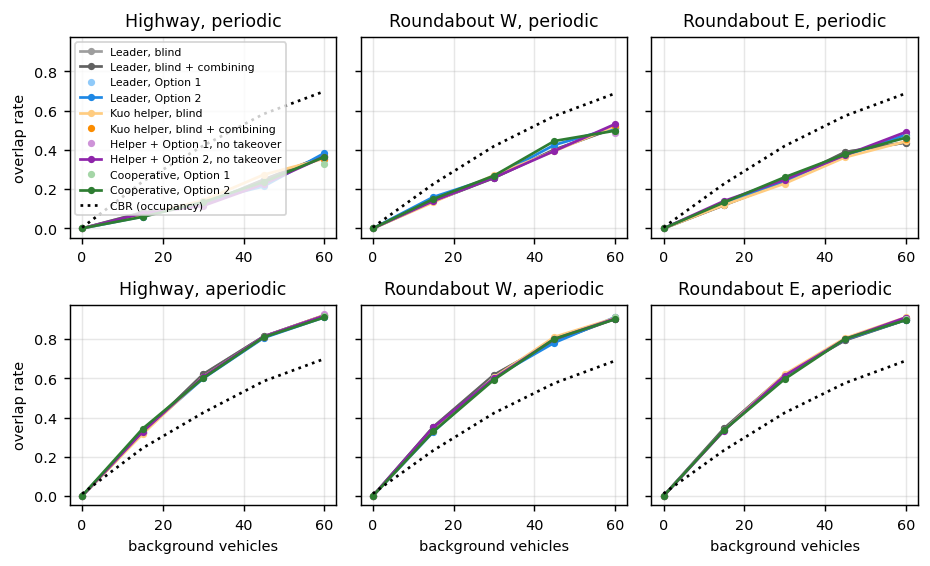

In [3]:
fig, ax = panels()
for i, tr in enumerate(TR):
    for j, sc in enumerate(SC):
        a = ax[i, j]
        d = runs[(runs.sc == sc) & (runs.tr == tr)]
        for arm in ORDER:
            g = d[d.arm == arm].groupby('nbg').overlap_rate.mean()
            # schemes run only at 0 and 60 cars: markers, no line (no data in between)
            ls = '-' if len(g) > 2 else 'none'
            if len(g):
                a.plot(g.index, g.values, marker='o', ms=3, ls=ls, color=COLOR[arm], label=LABEL[arm])
        c = d.groupby('nbg').cbr_occupied.mean()
        a.plot(c.index, c.values, 'k:', label='CBR (occupancy)')
        a.set_title(f'{SC[sc]}, {TR[tr]}')
        if i == 1: a.set_xlabel('background vehicles')
        if j == 0: a.set_ylabel('overlap rate')
ax[0, 0].legend(fontsize=6, ncol=1, loc='upper left')
save(fig, 'fig1_overlap_rate_vs_load')

## Fig. 2: does an overlap make a copy fail?
For every copy a member received before it held the TB: failure probability when the copy overlapped
(dark) and when it was clean (light). 60 background cars. The gap between the two bars is the part
of the failures that overlap adds; the light bar is what fails anyway (path loss, blockage, fading).

att_overlap_share  p_fail_overlap  p_fail_clean  \
sc   tr           arm                                                       
hwy  aperiodic1tb R1                  0.928           0.716         0.323   
                  R1_bsc              0.930           0.663         0.308   
                  R2                  0.925           0.639         0.266   
                  R3                  0.923           0.651         0.275   
                  R4                  0.934           0.650         0.214   
                  R4.1                0.940           0.623         0.199   
                  R4.2                0.934           0.626         0.191   
                  R4_bsc              0.935           0.634         0.209   
                  R5                  0.929           0.623         0.241   
                  R6                  0.922           0.629         0.238   
     periodic1tb  R1                  0.358           0.461         0.160   
                  R1_bsc              0.358           0.438         0.150   
                  R2                  0.339           0.407         0.128   
                  R3                  0.371           0.445         0.144   
                  R4                  0.356           0.390         0.113   
                  R4.1                0.362           0.394         0.110   
                  R4.2                0.366           0.370         0.106   
                  R4_bsc              0.357           0.380         0.111   
                  R5                  0.321           0.380         0.112   
                  R6                  0.354           0.382         0.110   
rbt  aperiodic1tb R1                  0.907           0.802         0.684   
                  R1_bsc              0.907           0.779         0.681   
                  R2                  0.911           0.756         0.674   
                  R3                  0.917           0.775         0.676   
                  R4                  0.915           0.721         0.534   
                  R4.1                0.917           0.696         0.534   
                  R4.2                0.913           0.699         0.517   
                  R4_bsc              0.916           0.705         0.520   
                  R5                  0.917           0.714         0.561   
                  R6                  0.905           0.717         0.576   
     periodic1tb  R1                  0.505           0.710         0.673   
                  R1_bsc              0.505           0.690         0.645   
                  R2                  0.519           0.645         0.613   
                  R3                  0.504           0.685         0.634   
                  R4                  0.523           0.592         0.474   
                  R4.1                0.484           0.548         0.451   
                  R4.2                0.530           0.566         0.444   
                  R4_bsc              0.523           0.577         0.459   
                  R5                  0.491           0.552         0.472   
                  R6                  0.482           0.567         0.474   
rbtE aperiodic1tb R1                  0.904           0.785         0.628   
                  R1_bsc              0.905           0.756         0.621   
                  R2                  0.909           0.733         0.590   
                  R3                  0.907           0.751         0.626   
                  R4                  0.919           0.702         0.445   
                  R4.1                0.916           0.665         0.456   
                  R4.2                0.919           0.668         0.449   
                  R4_bsc              0.918           0.685         0.453   
                  R5                  0.909           0.675         0.475   
                  R6                  0.905           0.673         0.472   
     periodic1tb  R1  

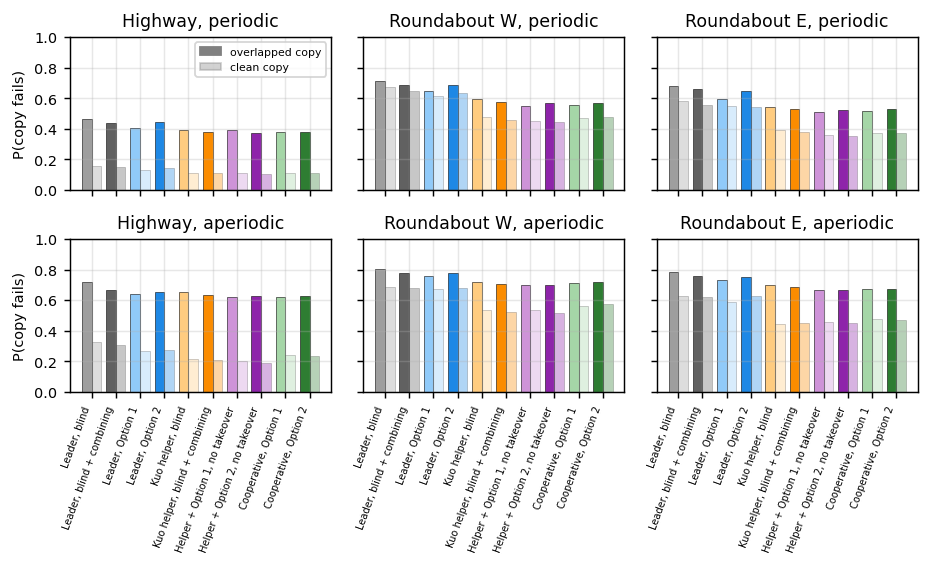

In [4]:
d60 = runs[(runs.nbg == 60) & (runs.camp == 'remote_full')]
fig, ax = panels()
x = np.arange(len(ORDER))
for i, tr in enumerate(TR):
    for j, sc in enumerate(SC):
        a = ax[i, j]
        g = d60[(d60.sc == sc) & (d60.tr == tr)].groupby('arm')[['p_fail_overlap', 'p_fail_clean']].mean().reindex(ORDER)
        a.bar(x - 0.2, g.p_fail_overlap, 0.4, color=[COLOR[k] for k in ORDER], edgecolor='k', lw=0.3)
        a.bar(x + 0.2, g.p_fail_clean, 0.4, color=[COLOR[k] for k in ORDER], alpha=0.35, edgecolor='k', lw=0.3)
        a.set_title(f'{SC[sc]}, {TR[tr]}'); a.set_ylim(0, 1)
        a.set_xticks(x); a.set_xticklabels([LABEL[k] for k in ORDER] if i == 1 else [], rotation=70, ha='right', fontsize=5.5)
        if j == 0: a.set_ylabel('P(copy fails)')
from matplotlib.patches import Patch
ax[0, 0].legend(handles=[Patch(color='grey', label='overlapped copy'), Patch(color='grey', alpha=0.35, label='clean copy')], fontsize=6)
save(fig, 'fig2_fail_given_overlap')
tab = d60.groupby(['sc', 'tr', 'arm'])[['att_overlap_share', 'p_fail_overlap', 'p_fail_clean']].mean()
tab['extra_fail_from_overlap'] = tab.att_overlap_share * (tab.p_fail_overlap - tab.p_fail_clean)
tab.round(3)

## Fig. 3: the simulator's loss-cause split
Lost (packet, member) pairs per packet and member, split as the simulator labels them: "collision" if any
failed copy of that packet overlapped, else "channel". Left of each pair: no background; right: 60 cars.

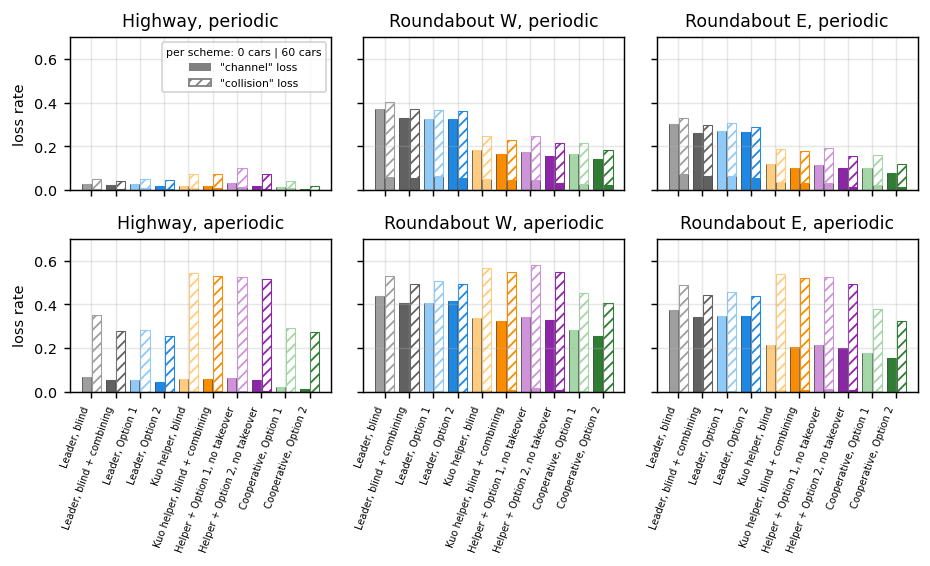

In [5]:
fig, ax = panels()
for i, tr in enumerate(TR):
    for j, sc in enumerate(SC):
        a = ax[i, j]
        for k, nbg in enumerate((0, 60)):
            g = runs[(runs.sc == sc) & (runs.tr == tr) & (runs.nbg == nbg) & (runs.camp == 'remote_full')]
            g = g.groupby('arm')[['collision_loss', 'channel_loss']].mean().reindex(ORDER)
            xs = x * 2.4 + k
            a.bar(xs, g.channel_loss, 0.9, color=[COLOR[a_] for a_ in ORDER], edgecolor='k', lw=0.3, hatch='' if k else '')
            a.bar(xs, g.collision_loss, 0.9, bottom=g.channel_loss, color='white', edgecolor=[COLOR[a_] for a_ in ORDER], hatch='////', lw=0.6)
        a.set_title(f'{SC[sc]}, {TR[tr]}'); a.set_ylim(0, 0.7)
        a.set_xticks(x * 2.4 + 0.5); a.set_xticklabels([LABEL[k] for k in ORDER] if i == 1 else [], rotation=70, ha='right', fontsize=5.5)
        if j == 0: a.set_ylabel('loss rate')
from matplotlib.patches import Patch
ax[0, 0].legend(handles=[Patch(facecolor='grey', label='"channel" loss'),
                         Patch(facecolor='white', edgecolor='grey', hatch='////', label='"collision" loss')],
                title='per scheme: 0 cars | 60 cars', title_fontsize=6, fontsize=6)
save(fig, 'fig3_loss_split')

## Fig. 4: how far is the nearest overlapping transmitter?
Overlapped copies at 60 background cars, all schemes pooled: CDF of the distance from the transmitter to
the nearest vehicle sending on a common subchannel in the same slot, for copies that failed and copies
that were decoded anyway.

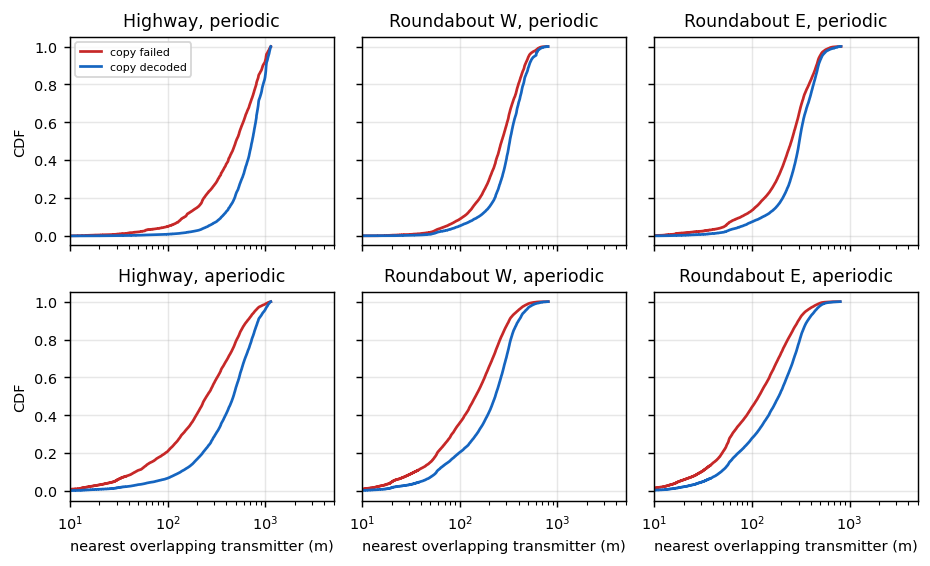

In [6]:
fig, ax = panels(sharex=True)
n60 = near[near.nbg == 60]
for i, tr in enumerate(TR):
    for j, sc in enumerate(SC):
        a = ax[i, j]
        g = n60[(n60.sc == sc) & (n60.tr == tr)]
        for f, col, lab in ((1, '#c62828', 'copy failed'), (0, '#1565c0', 'copy decoded')):
            v = np.sort(g[g.fail == f].nearest_collider_m.values)
            a.plot(v, np.arange(1, len(v) + 1) / len(v), color=col, label=lab)
        a.set_xscale('log'); a.set_xlim(10, 5000); a.set_title(f'{SC[sc]}, {TR[tr]}')
        if i == 1: a.set_xlabel('nearest overlapping transmitter (m)')
        if j == 0: a.set_ylabel('CDF')
ax[0, 0].legend(fontsize=6)
save(fig, 'fig4_nearest_collider_cdf')

## Consistency checks
Result of `checks.py` over every run (counters of `_run.csv` against each other and against the
per-row logs). Explanations of the failing checks are in `CHECKS.md`.

In [7]:
pd.read_csv('checks_summary.csv').query('failed > 0')

,check,runs,failed
1,new_tb = pkts (one TB per packet),2280,209
2,tx_per_pkt = (leader_tx + helper_tx)/pkts,2280,283
4,leader_tx = rows of _ltx in window,1200,5
6,leader_tx_coll_rate = share of ltx with n_coll>0,1200,2
10,nack_rx <= nack_sent,2280,820
12,blind: leader_tx = 3 x new_tb (leader alone),600,44
21,zero: relay_after_allack,2280,1
37,pkt n_att <= 3,2280,179
39,copies per TB (leader + helper) <= 3,1200,90
40,no member decodes the same TB twice,1200,347
